# Module 4: Customer Analytics: Churn & Customer Lifetime Value

**Business question:** Which customers should relationship managers prioritise for retention? If NovaFin can contact only **1,000 customers**, who should they be?

**Chain:** customer data → P(churn) → customer lifetime value (CLV) → value at risk = P(churn) × CLV → 2×2 segments → target list of 1,000.

**What you will learn:** modelling a very rare event (89 churners in 5,000), recognising when a model has *no* signal, building a CLV formula, segmentation, and ranking under a budget.

## 0. Setup

In [1]:
import warnings; warnings.filterwarnings("ignore")
import sys, subprocess, importlib.util
if importlib.util.find_spec("google.colab"):             # Colab: install the extra libraries once
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "shap", "xgboost", "lightgbm", "imbalanced-learn"])
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
try:
    from google.colab import drive; drive.mount("/content/drive")
except ImportError:
    pass
CANDIDATES = [Path("/content/drive/MyDrive/NovaFin_Capstone/data"), Path("../../Project"), Path("/mnt/project-files/Project")]
DATA = next(p for p in CANDIDATES if (p / "nova_customers.csv").exists())
OUT = DATA.parent / "outputs" if "drive" in str(DATA) else Path("../outputs")
OUT.mkdir(exist_ok=True, parents=True)
SEED = 42
sns.set_theme(style="whitegrid", palette="deep")

## 1. Load and inspect
This file is analysed on its own: its customer IDs do not match the loan or transaction files.

In [2]:
df = pd.read_csv(DATA / "nova_customers.csv")
print(df.shape, "| missing:", df.isna().sum().sum())
print(f"Churn rate: {df.Churn_Flag.mean():.2%} ({df.Churn_Flag.sum()} churners)")
df.head()

(5000, 13) | missing: 0
Churn rate: 1.78% (89 churners)


,Customer_ID,Age,Annual_Income,Account_Balance,Products_Held,Transactions_Per_Month,Digital_Usage,Complaints,Loan_Balance,Investment_Balance,Relationship_Length_Years,Churn_Flag,Estimated_CLV
0,300001,51,515268.04,898438.26,2,12,71.29,1,392907.06,1933423.83,3,0,82080.38
1,300002,29,1991863.53,87131.43,4,16,57.60,0,84011.88,221005.37,10,0,87274.72
2,300003,55,2407704.14,886429.96,1,19,93.20,2,1326810.53,2657738.86,7,0,176662.09
3,300004,56,499119.56,188830.95,5,21,49.78,1,121135.72,526083.05,16,0,31552.83
4,300005,55,2855843.50,595025.85,1,17,100.00,2,323896.82,1649877.84,6,0,155669.08


## 2. Exploratory analysis
Do churners look different from customers who stay?

In [3]:
feats = ["Age", "Annual_Income", "Account_Balance", "Products_Held", "Transactions_Per_Month", "Digital_Usage",
         "Complaints", "Loan_Balance", "Investment_Balance", "Relationship_Length_Years"]
comp = df.groupby("Churn_Flag")[feats].mean().T
comp["difference %"] = (comp[1] / comp[0] - 1) * 100
comp.round(1)

Churn_Flag,0,1,difference %
Age,48.1,47.5,-1.3
Annual_Income,1059234.0,987587.2,-6.8
Account_Balance,452988.5,496683.5,9.6
Products_Held,3.5,3.4,-2.0
Transactions_Per_Month,19.0,19.0,0.2
Digital_Usage,64.5,60.9,-5.6
Complaints,1.5,1.6,6.9
Loan_Balance,455871.7,491602.6,7.8
Investment_Balance,657237.6,594424.5,-9.6
Relationship_Length_Years,10.0,9.8,-1.8


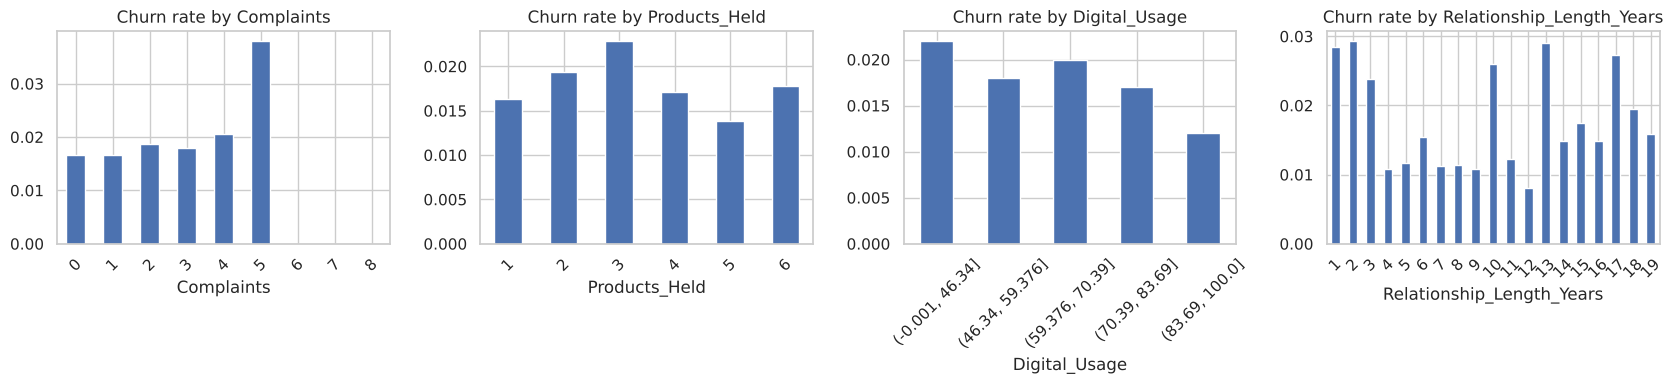

In [4]:
fig, ax = plt.subplots(1, 4, figsize=(17, 4))
for a, c in zip(ax, ["Complaints", "Products_Held", "Digital_Usage", "Relationship_Length_Years"]):
    df.groupby(c if df[c].nunique() < 20 else pd.qcut(df[c], 5), observed=True)["Churn_Flag"].mean().plot.bar(ax=a, title=f"Churn rate by {c}", rot=45)
plt.tight_layout(); plt.show()

**What the EDA says:** churners and stayers look almost identical: every average differs by a few percent, and churn rates by complaints, products or digital usage show no clear pattern. Expect a weak model. Spotting this early is part of good analysis.

## 3. Churn models
With only 89 churners, a single test set would hold ~27 of them, too few to trust. We use **repeated stratified 5-fold CV** (50 scores per model) and class weights.

In [5]:
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

X = df[feats].copy()
X["Total_Balance"] = X["Account_Balance"] + X["Investment_Balance"]
X["Balance_to_Income"] = X["Total_Balance"] / X["Annual_Income"]
y = df["Churn_Flag"]
spw = (y == 0).sum() / (y == 1).sum()
models = {
    "Logistic (balanced)": make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", C=0.1, max_iter=2000)),
    "Random forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=20, class_weight="balanced_subsample", random_state=SEED, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=200, max_depth=2, learning_rate=0.05, scale_pos_weight=spw, random_state=SEED, verbosity=0),
}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED)
scores = {n: cross_val_score(m, X, y, cv=cv, scoring="roc_auc") for n, m in models.items()}
pd.DataFrame({n: [s.mean(), s.std(), np.percentile(s, 5), np.percentile(s, 95)] for n, s in scores.items()}, index=["mean AUC", "std", "5th pct", "95th pct"]).T.round(3)

,mean AUC,std,5th pct,95th pct
Logistic (balanced),0.498,0.058,0.392,0.585
Random forest,0.490,0.055,0.391,0.578
XGBoost,0.504,0.060,0.417,0.601


**Reading the result:** every model's AUC is around 0.5, and the 5th–95th percentile range spans 0.5. **The churn label cannot be predicted from these variables.** A good analyst reports that clearly rather than presenting a random model as insight.

**What it means for NovaFin:** the bank is not capturing the data that signals churn (for example falling balances month to month, competitor offers, service events). Recommendation: start collecting behavioural *trends*, not just snapshots.

We still produce out-of-fold churn scores (they will sit close to the 1.8% base rate) to show the full method, which will work once better data exists.

In [6]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
raw = cross_val_predict(models["Logistic (balanced)"], X, y, cv=skf, method="predict_proba")[:, 1]
# class weights inflate probabilities; rescale so the average equals the true churn rate
df["P_Churn"] = raw * y.mean() / raw.mean()
print("Out-of-fold AUC:", round(roc_auc_score(y, df.P_Churn), 3), "| mean P(churn):", round(df.P_Churn.mean(), 4))

Out-of-fold AUC: 0.448 | mean P(churn): 0.0178


## 4. Customer Lifetime Value
**Check the provided column first.** A linear regression of `Estimated_CLV` on the other columns fits almost perfectly, so it is a fixed formula, not data.

In [7]:
from sklearn.linear_model import LinearRegression
lin = LinearRegression().fit(df[feats], df["Estimated_CLV"])
print("R² of Estimated_CLV on the other columns:", round(lin.score(df[feats], df["Estimated_CLV"]), 5))
pd.Series(lin.coef_, index=feats).round(4)

R² of Estimated_CLV on the other columns: 0.99996


Age                             0.4209
Annual_Income                   0.0400
Account_Balance                 0.0300
Products_Held                  -0.8948
Transactions_Per_Month         -0.3553
Digital_Usage                  -0.1466
Complaints                  -4977.0305
Loan_Balance                    0.0120
Investment_Balance              0.0180
Relationship_Length_Years       0.3030
dtype: float64

It is roughly 4% of income + 3% of account balance + 1.8% of investments + 1.2% of loans − ₹5,000 per complaint. It ignores churn and time. We build our own, finance-based CLV:

$$CLV = \sum_{t=1}^{5} \frac{M \cdot (1-p)^{t}}{(1+d)^{t}}$$

**Assumptions:** annual margin M = 2.0% of account balance (deposit spread) + 2.5% of loan balance (net interest margin) + 1.0% of investment balance (fees) − ₹1,000 servicing cost per complaint; p = annual churn probability; d = 10% discount rate; 5-year horizon.

In [8]:
H, DISC = 5, 0.10
df["Annual_Margin"] = (0.020 * df.Account_Balance + 0.025 * df.Loan_Balance + 0.010 * df.Investment_Balance - 1000 * df.Complaints).clip(lower=0)
ret = 1 - df["P_Churn"]
df["CLV"] = sum(df["Annual_Margin"] * ret ** t / (1 + DISC) ** t for t in range(1, H + 1))
print("Correlation of our CLV with Estimated_CLV:", round(df[["CLV", "Estimated_CLV"]].corr().iloc[0, 1], 3))
df[["CLV", "Estimated_CLV"]].describe().round(0)

Correlation of our CLV with Estimated_CLV: 0.73


,CLV,Estimated_CLV
count,5000.0,5000.0
mean,92092.0,65602.0
std,110583.0,46242.0
min,0.0,0.0
25%,27360.0,34591.0
50%,57038.0,54205.0
75%,112303.0,83622.0
max,1256448.0,439367.0


## 5. 2×2 segmentation
- **CLV split:** median CLV.
- **Churn split:** top 20% of predicted churn risk = High churn.

In [9]:
hi_clv = df.CLV >= df.CLV.median()
hi_churn = df.P_Churn >= df.P_Churn.quantile(0.80)
df["Segment"] = np.select([hi_clv & ~hi_churn, hi_clv & hi_churn, ~hi_clv & ~hi_churn], ["Protect", "Priority retention", "Maintain"], "Low-cost intervention")
seg = df.groupby("Segment").agg(customers=("Customer_ID", "count"), avg_CLV=("CLV", "mean"), total_CLV_cr=("CLV", lambda s: s.sum() / 1e7),
                                avg_P_churn=("P_Churn", "mean"), actual_churn=("Churn_Flag", "mean")).round(4)
seg.loc[["Protect", "Priority retention", "Maintain", "Low-cost intervention"]]

,customers,avg_CLV,total_CLV_cr,avg_P_churn,actual_churn
Segment,,,,,
Protect,1935,149371.5125,28.9034,0.0162,0.0253
Priority retention,565,179946.2664,10.1670,0.0231,0.0159
Maintain,2065,28416.0606,5.8679,0.0169,0.0126
Low-cost intervention,435,25466.8700,1.1078,0.0222,0.0115


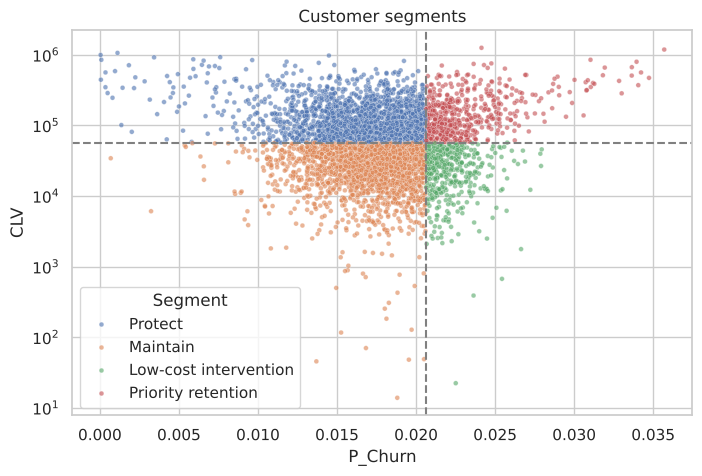

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=df, x="P_Churn", y="CLV", hue="Segment", s=12, ax=ax, alpha=0.6)
ax.set(yscale="log", title="Customer segments"); ax.axvline(df.P_Churn.quantile(0.8), c="grey", ls="--"); ax.axhline(df.CLV.median(), c="grey", ls="--"); plt.show()

## 6. The 1,000 customers to contact
Rank by **expected value at risk** = P(churn) × CLV, the money NovaFin expects to lose from each customer, and take the top 1,000.

In [11]:
df["Value_at_Risk"] = df["P_Churn"] * df["CLV"]
top = df.nlargest(1000, "Value_at_Risk")
rng = np.random.default_rng(SEED)
rand = df.iloc[rng.choice(len(df), 1000, replace=False)]
compare = pd.DataFrame({
    "Top 1,000 by value at risk": [top.Value_at_Risk.sum() / 1e7, top.CLV.sum() / 1e7, top.Churn_Flag.sum()],
    "Random 1,000": [rand.Value_at_Risk.sum() / 1e7, rand.CLV.sum() / 1e7, rand.Churn_Flag.sum()],
}, index=["Value at risk (₹ crore)", "CLV covered (₹ crore)", "Actual churners reached"]).round(3)
compare["lift"] = (compare.iloc[:, 0] / compare.iloc[:, 1]).round(2)
compare

,"Top 1,000 by value at risk","Random 1,000",lift
Value at risk (₹ crore),0.466,0.168,2.77
CLV covered (₹ crore),24.730,9.702,2.55
Actual churners reached,20.000,18.000,1.11


In [12]:
top.Segment.value_counts()

Segment
Protect               645
Priority retention    355
Name: count, dtype: int64

**Answer to the executive question:** contact the 1,000 customers with the highest value at risk, mostly *Priority retention* and *Protect* customers. Because churn is not predictable, the ranking is driven by **CLV**: the list covers about 2.5× more customer value than a random 1,000. It does not reach more actual churners than random, and we should say so.

## 7. Save outputs

In [13]:
top[["Customer_ID", "P_Churn", "CLV", "Value_at_Risk", "Segment"]].round(4).to_csv(OUT / "m4_top1000_contact_list.csv", index=False)
df[["Customer_ID", "P_Churn", "CLV", "Estimated_CLV", "Segment"]].round(4).to_csv(OUT / "m4_customers_scored.csv", index=False)
pd.Series({"cv_auc": np.mean(scores["Logistic (balanced)"]), "total_clv_cr": df.CLV.sum() / 1e7, "top1000_clv_cr": top.CLV.sum() / 1e7,
           "top1000_value_at_risk_cr": top.Value_at_Risk.sum() / 1e7, "investment_balance_cr": df.Investment_Balance.sum() / 1e7}).to_csv(OUT / "m4_summary.csv")
print("Saved")

Saved


## 8. Conclusions
1. **Churn is not predictable** with the current data (cross-validated AUC ≈ 0.5 for every model). This is the key, honest finding.
2. `Estimated_CLV` is a fixed linear formula; we built a CLV from margins, retention and discounting instead.
3. **Target list:** the top 1,000 by value at risk, which covers about 2.5× the customer value of a random list.
4. **Recommendation:** run the retention campaign as a controlled test (contact half, hold out half) to measure the real effect, and collect monthly behaviour trends so a churn model can work next year.
5. **Limits:** assumed margins and discount rate; churn probability is near the base rate for everyone.